# 4 – Tarea 2: Regresión

**Objetivo:** Predecir la nota media obtenida en el segundo semestre (`nota_media_2sem`).

**Restricción metodológica:** No se usan variables del 2do semestre. Solo usamos:
- Características del estudiante al momento de matricularse
- Variables del primer semestre
- Variables macroeconómicas

**Modelos:**
1. Regresión Lineal 
2. Ridge / Lasso (regularización)
3. Random Forest Regressor
4. Gradient Boosting Regressor

**Métricas:** RMSE y R² como métricas principales.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import cross_val_score, GridSearchCV

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')

# Cargamos datos
X_train = np.load('datos_procesados/X_train_reg.npy')
X_test  = np.load('datos_procesados/X_test_reg.npy')
y_train = np.load('datos_procesados/y_train_reg.npy')
y_test  = np.load('datos_procesados/y_test_reg.npy')
X_train_s = np.load('datos_procesados/X_train_reg_scaled.npy')
X_test_s  = np.load('datos_procesados/X_test_reg_scaled.npy')

features_reg = pd.read_csv('datos_procesados/features_reg.csv').iloc[:, 0].tolist()

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Target (nota_media_2sem): media={y_train.mean():.2f}, std={y_train.std():.2f}")


Train: (2843, 208), Test: (711, 208)
Target (nota_media_2sem): media=12.74, std=1.38


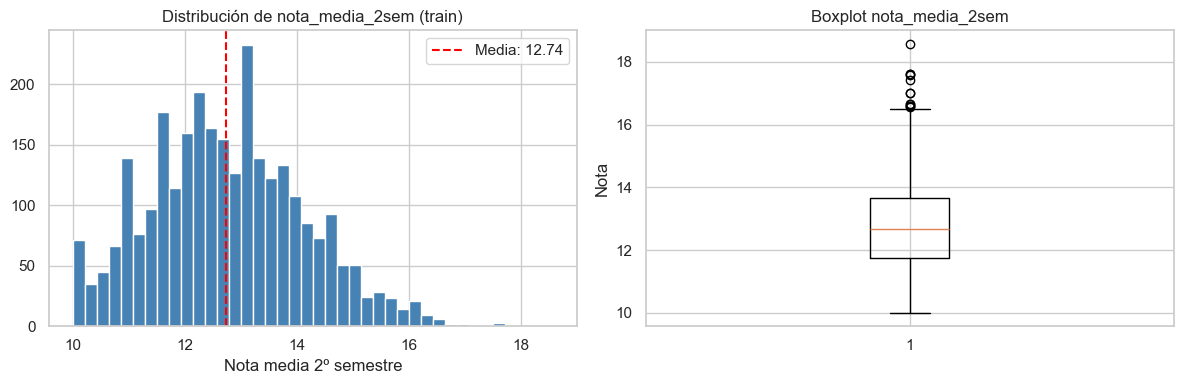

Rango: [10.00, 18.57]


In [ ]:
# Visualizamos la distribución del target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=40, color='steelblue', edgecolor='white')
axes[0].set_title("Distribución de nota_media_2sem (train)")
axes[0].set_xlabel("Nota media 2º semestre")
axes[0].axvline(y_train.mean(), color='red', linestyle='--', label=f"Media: {y_train.mean():.2f}")
axes[0].legend()

axes[1].boxplot(y_train, vert=True)
axes[1].set_title("Boxplot nota_media_2sem")
axes[1].set_ylabel("Nota")

plt.tight_layout()
plt.show()
print(f"Rango: [{y_train.min():.2f}, {y_train.max():.2f}]")


## 4.0 Análisis exploratorio: Correlaciones

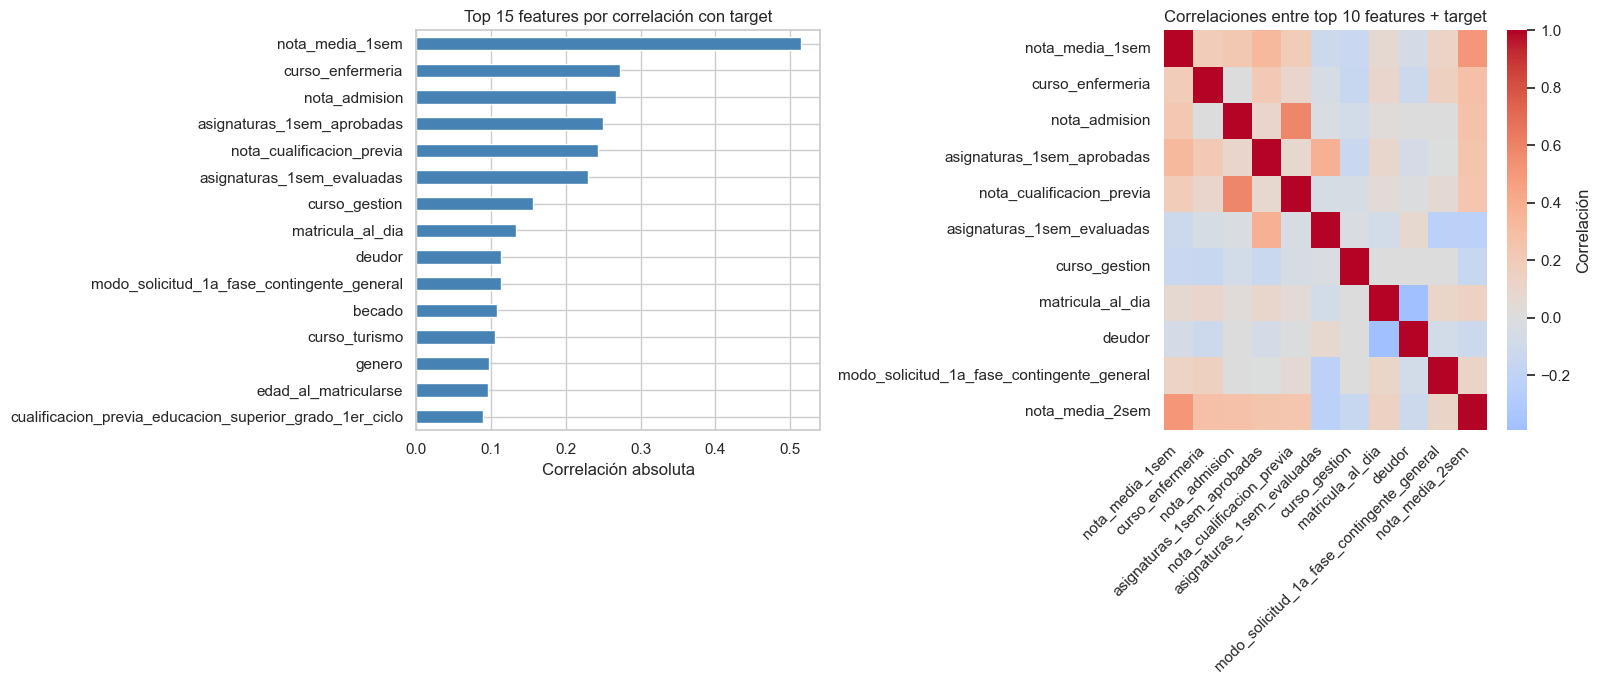


Top 10 features correlacionadas con nota_media_2sem:
nota_media_1sem                               0.514755
curso_enfermeria                              0.272284
nota_admision                                 0.267399
asignaturas_1sem_aprobadas                    0.249207
nota_cualificacion_previa                     0.242463
asignaturas_1sem_evaluadas                    0.230125
curso_gestion                                 0.156113
matricula_al_dia                              0.133066
deudor                                        0.113577
modo_solicitud_1a_fase_contingente_general    0.113541
Name: nota_media_2sem, dtype: float64


In [ ]:
# Correlación con el target y multicolinealidad
X_full = np.concatenate([X_train, y_train.reshape(-1, 1)], axis=1)
feature_cols = features_reg + ['nota_media_2sem']
corr_matrix = pd.DataFrame(X_full, columns=feature_cols).corr()

# Top features correlacionadas con el target
target_corr = corr_matrix['nota_media_2sem'].drop('nota_media_2sem').abs().sort_values(ascending=False)
top_corr_features = target_corr.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top correlated features
top_corr_features.sort_values().plot(kind='barh', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title("Top 15 features por correlación con target")
axes[0].set_xlabel("Correlación absoluta")

# Heatmap de top features
top_features_list = top_corr_features.head(10).index.tolist()
top_features_list.append('nota_media_2sem')
heatmap_data = pd.DataFrame(X_full, columns=feature_cols)[top_features_list].corr()
sns.heatmap(heatmap_data, annot=False, cmap='coolwarm', center=0, ax=axes[1], cbar_kws={'label': 'Correlación'})
axes[1].set_title("Correlaciones entre top 10 features + target")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, horizontalalignment='right')

plt.tight_layout()
plt.savefig("plots/correlation_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nTop 10 features correlacionadas con nota_media_2sem:")
print(top_corr_features.head(10))

## 4.1 Función de evaluación y gráficas

In [ ]:
# Evaluacion y visualizacion de resultados en gráficas
def evaluar_regresion(nombre, y_true, y_pred, cv_scores=None):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print("-"*50)
    print(f"Modelo: {nombre}")
    print(f"  RMSE:  {rmse:.4f}")
    print(f"  MAE:   {mae:.4f}")
    print(f"  R²:    {r2:.4f}")
    if cv_scores is not None:
        print(f"  CV R² (5-fold): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    return {"Modelo": nombre, "RMSE": rmse, "MAE": mae, "R²": r2, "y_pred": y_pred}

def plot_predictions(y_true, y_pred, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    lims = [min(y_true.min(), y_pred.min()) - 0.5, max(y_true.max(), y_pred.max()) + 0.5]
    axes[0].scatter(y_true, y_pred, alpha=0.3, color='steelblue', s=15)
    axes[0].plot(lims, lims, 'r--', label="Predicción perfecta")
    axes[0].set_xlabel("Nota real")
    axes[0].set_ylabel("Nota predicha")
    axes[0].set_title(f"Real vs Predicho – {title}")
    axes[0].legend()
    axes[0].set_xlim(lims)
    axes[0].set_ylim(lims)
    
    residuos = y_true - y_pred
    axes[1].hist(residuos, bins=40, color='steelblue', edgecolor='white')
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title("Distribución de residuos")
    axes[1].set_xlabel("Residuo")
    plt.tight_layout()
    return fig, residuos

def plot_qq(residuos, title):
    from scipy import stats
    fig, ax = plt.subplots(figsize=(8, 6))
    stats.probplot(residuos, dist="norm", plot=ax)
    ax.set_title(f"Q-Q Plot – {title}")
    plt.tight_layout()
    return fig

def plot_residuals_vs_fitted(y_true, y_pred, title):
    residuos = y_true - y_pred
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(y_pred, residuos, alpha=0.3, color='steelblue', s=15)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xlabel("Valores ajustados")
    ax.set_ylabel("Residuos")
    ax.set_title(f"Residuos vs Ajustados – {title}")
    plt.tight_layout()
    return fig

def error_by_range(y_true, y_pred, title, n_bins=5):
    errors = np.abs(y_true - y_pred)
    bins = pd.qcut(y_true, q=n_bins, duplicates='drop')
    error_by_bin = pd.DataFrame({'error': errors, 'range': bins}).groupby('range')['error'].agg(['mean', 'std'])
    
    fig, ax = plt.subplots(figsize=(10, 5))
    error_by_bin['mean'].plot(kind='bar', ax=ax, color='coral', edgecolor='white', legend=False)
    ax.errorbar(range(len(error_by_bin)), error_by_bin['mean'], yerr=error_by_bin['std'], fmt='none', color='black', capsize=5)
    ax.set_title(f"MAE por rango de nota – {title}")
    ax.set_xlabel("Rango de nota")
    ax.set_ylabel("MAE")
    ax.set_xticklabels([f"{interval.left:.1f}-{interval.right:.1f}" for interval in error_by_bin.index], rotation=45)
    plt.tight_layout()
    return fig

In [ ]:
# Iniciamos o reiniciamos la lista de resultados antes de entrenar modelos
resultados_reg = []

## 4.2 Regresión Lineal

--------------------------------------------------
Modelo: Regresión Lineal
  RMSE:  1.0716
  MAE:   0.8425
  R²:    0.3801
  CV R² (5-fold): 0.3401 ± 0.0312


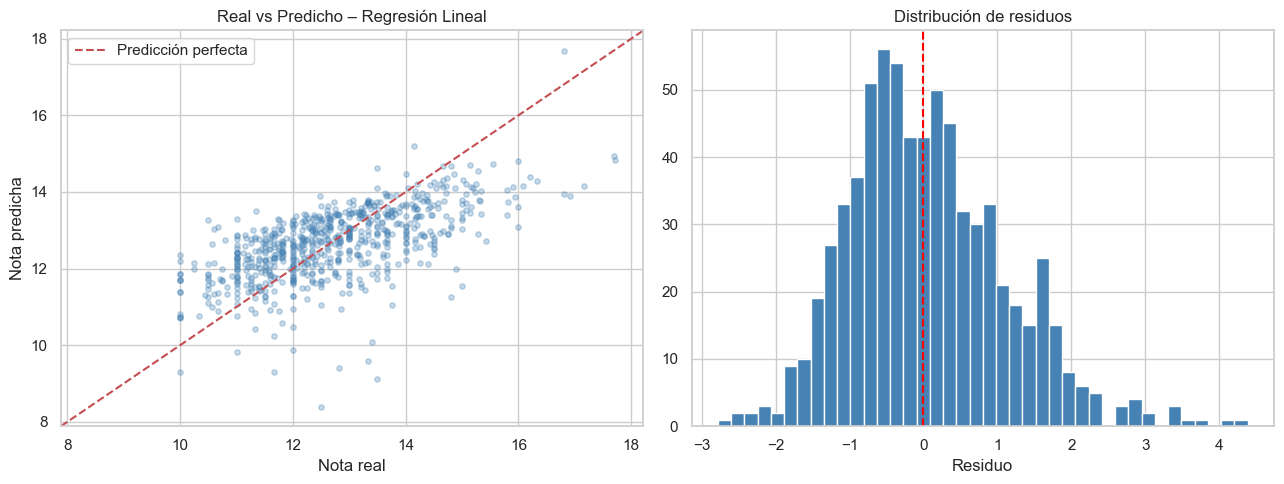

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_s, y_train)
y_pred_lin_reg = lin_reg.predict(X_test_s)
cv_scores_lin = cross_val_score(lin_reg, X_train_s, y_train, cv=5, scoring='r2')
resultados_reg.append(evaluar_regresion("Regresión Lineal", y_test, y_pred_lin_reg, cv_scores_lin))

fig, residuos_lin = plot_predictions(y_test, y_pred_lin_reg, "Regresión Lineal")
plt.savefig("plots/lin_reg_predictions.png", dpi=150, bbox_inches='tight')
plt.show()

## 4.3 Ridge y Lasso

In [ ]:
param_grid_ridge = {"alpha": [0.01, 0.1, 1, 10, 100]}
gs_ridge = GridSearchCV(Ridge(), param_grid_ridge, cv=5, scoring="r2", n_jobs=-1)
gs_ridge.fit(X_train_s, y_train)
ridge_best = gs_ridge.best_estimator_
y_pred_ridge = ridge_best.predict(X_test_s)
cv_scores_ridge = cross_val_score(ridge_best, X_train_s, y_train, cv=5, scoring='r2')
resultados_reg.append(evaluar_regresion(f"Ridge (α={gs_ridge.best_params_['alpha']})", y_test, y_pred_ridge, cv_scores_ridge))

param_grid_lasso = {"alpha": [0.001, 0.01, 0.1, 1, 10]}
gs_lasso = GridSearchCV(Lasso(max_iter=5000), param_grid_lasso, cv=5, scoring="r2", n_jobs=-1)
gs_lasso.fit(X_train_s, y_train)
lasso_best = gs_lasso.best_estimator_
y_pred_lasso = lasso_best.predict(X_test_s)
cv_scores_lasso = cross_val_score(lasso_best, X_train_s, y_train, cv=5, scoring='r2')
resultados_reg.append(evaluar_regresion(f"Lasso (α={gs_lasso.best_params_['alpha']})", y_test, y_pred_lasso, cv_scores_lasso))

n_zero = (lasso_best.coef_ == 0).sum()
print(f"\nLasso: {n_zero} variables anuladas de {len(features_reg)} ({100*n_zero/len(features_reg):.1f}%)")

--------------------------------------------------
Modelo: Ridge (α=100)
  RMSE:  1.0673
  MAE:   0.8422
  R²:    0.3851
  CV R² (5-fold): 0.3534 ± 0.0284
--------------------------------------------------
Modelo: Lasso (α=0.01)
  RMSE:  1.0598
  MAE:   0.8317
  R²:    0.3937
  CV R² (5-fold): 0.3769 ± 0.0255

Lasso: 89 variables anuladas de 208 (42.8%)


## 4.4 Random Forest Regressor

In [ ]:
param_grid_rfr = {"n_estimators": [100, 200], "max_depth": [10, 20, None], "min_samples_leaf": [1, 5]}
gs_rfr = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), param_grid_rfr, cv=5, scoring="r2", n_jobs=-1)
gs_rfr.fit(X_train, y_train)
rfr_best = gs_rfr.best_estimator_
y_pred_rfr = rfr_best.predict(X_test)
cv_scores_rfr = cross_val_score(rfr_best, X_train, y_train, cv=5, scoring='r2')
resultados_reg.append(evaluar_regresion("Random Forest Regressor", y_test, y_pred_rfr, cv_scores_rfr))
print(f"Mejores params: {gs_rfr.best_params_}")

--------------------------------------------------
Modelo: Random Forest Regressor
  RMSE:  0.9264
  MAE:   0.7084
  R²:    0.5367
  CV R² (5-fold): 0.5106 ± 0.0160
Mejores params: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}


## 4.5 Gradient Boosting Regressor

In [ ]:
param_grid_gbr = {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}
gs_gbr = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid_gbr, cv=5, scoring="r2", n_jobs=-1)
gs_gbr.fit(X_train, y_train)
gbr_best = gs_gbr.best_estimator_
y_pred_gbr = gbr_best.predict(X_test)
cv_scores_gbr = cross_val_score(gbr_best, X_train, y_train, cv=5, scoring='r2')
resultados_reg.append(evaluar_regresion("Gradient Boosting Regressor", y_test, y_pred_gbr, cv_scores_gbr))
print(f"Mejores params: {gs_gbr.best_params_}")

--------------------------------------------------
Modelo: Gradient Boosting Regressor
  RMSE:  0.9353
  MAE:   0.7189
  R²:    0.5278
  CV R² (5-fold): 0.5133 ± 0.0226
Mejores params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}


## 4.6 Comparativa


COMPARATIVA DE MODELOS
                     Modelo     RMSE      MAE       R²
    Random Forest Regressor 0.926444 0.708385 0.536690
Gradient Boosting Regressor 0.935286 0.718886 0.527804
             Lasso (α=0.01) 1.059788 0.831710 0.393722
              Ridge (α=100) 1.067284 0.842183 0.385115
           Regresión Lineal 1.071599 0.842466 0.380133


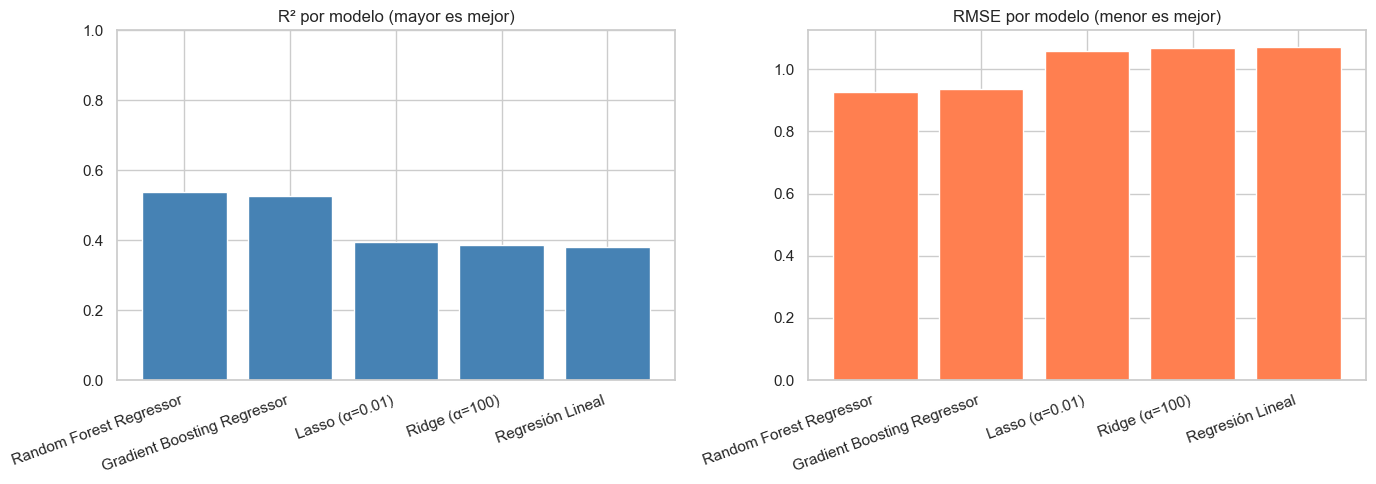


✓ Mejor modelo: Random Forest Regressor


In [ ]:
df_res = pd.DataFrame(resultados_reg)[['Modelo', 'RMSE', 'MAE', 'R²']].sort_values("R²", ascending=False)
print("\n" + "="*60)
print("COMPARATIVA DE MODELOS")
print("="*60)
print(df_res.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
modelos = df_res["Modelo"]
x = np.arange(len(modelos))

axes[0].bar(x, df_res["R²"], color='steelblue', edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(modelos, rotation=20, ha='right')
axes[0].set_title("R² por modelo (mayor es mejor)")
axes[0].set_ylim(0, 1)

axes[1].bar(x, df_res["RMSE"], color='coral', edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(modelos, rotation=20, ha='right')
axes[1].set_title("RMSE por modelo (menor es mejor)")

plt.tight_layout()
plt.savefig("plots/comparativa_regresion.png", dpi=150, bbox_inches='tight')
plt.show()

mejor_modelo_nombre = df_res.iloc[0]["Modelo"]
print(f"\n✓ Mejor modelo: {mejor_modelo_nombre}")

## 4.7 Análisis del mejor modelo de regresión


Análisis del mejor modelo: Random Forest Regressor



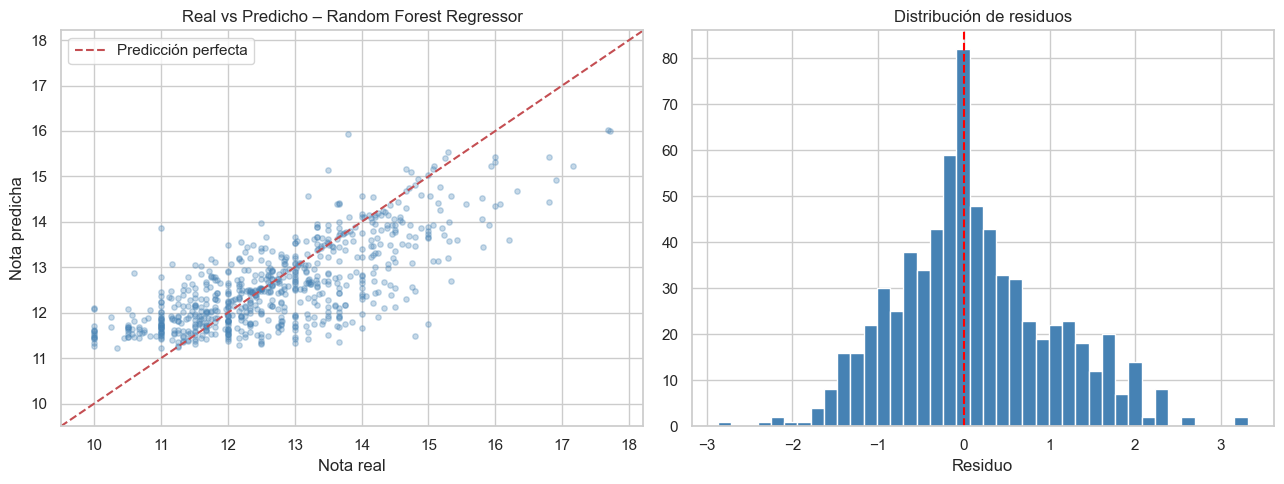

In [ ]:
# Map predictions and models dynamically
models_dict = {
    "Regresión Lineal": {"model": lin_reg, "preds": y_pred_lin_reg},
    f"Ridge (α={gs_ridge.best_params_['alpha']})": {"model": ridge_best, "preds": y_pred_ridge},
    f"Lasso (α={gs_lasso.best_params_['alpha']})": {"model": lasso_best, "preds": y_pred_lasso},
    "Random Forest Regressor": {"model": rfr_best, "preds": y_pred_rfr},
    "Gradient Boosting Regressor": {"model": gbr_best, "preds": y_pred_gbr}
}

mejor_modelo_nombre = df_res.iloc[0]["Modelo"]
y_pred_mejor = models_dict[mejor_modelo_nombre]["preds"]
modelo_mejor = models_dict[mejor_modelo_nombre]["model"]

print(f"\nAnálisis del mejor modelo: {mejor_modelo_nombre}\n")

fig, residuos_mejor = plot_predictions(y_test, y_pred_mejor, mejor_modelo_nombre)
plt.savefig("plots/scatter_regresion_mejor.png", dpi=150, bbox_inches='tight')
plt.show()

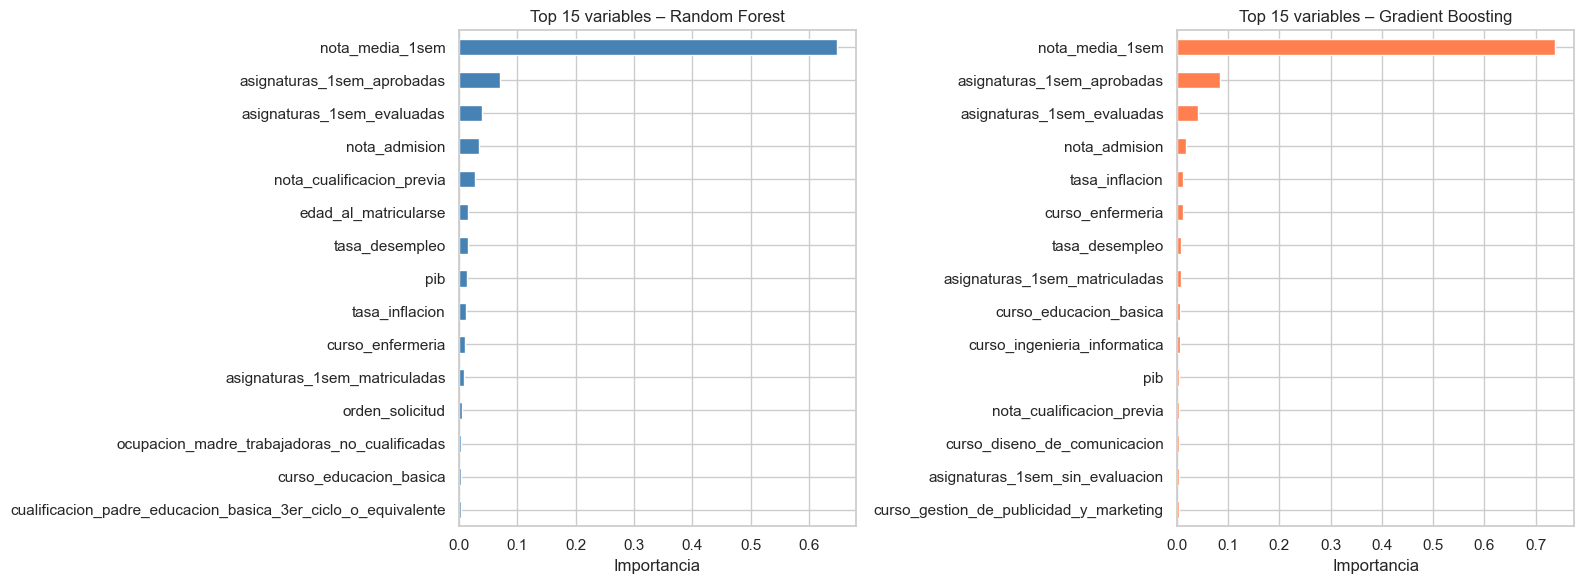

In [ ]:
# Feature importance for tree-based models
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Random Forest importance
if hasattr(rfr_best, "feature_importances_"):
    imp_rf = pd.Series(rfr_best.feature_importances_, index=features_reg).nlargest(15).sort_values()
    imp_rf.plot(kind='barh', ax=axes[0], color='steelblue', edgecolor='white')
    axes[0].set_title("Top 15 variables – Random Forest")
    axes[0].set_xlabel("Importancia")

# Gradient Boosting importance
if hasattr(gbr_best, "feature_importances_"):
    imp_gbr = pd.Series(gbr_best.feature_importances_, index=features_reg).nlargest(15).sort_values()
    imp_gbr.plot(kind='barh', ax=axes[1], color='coral', edgecolor='white')
    axes[1].set_title("Top 15 variables – Gradient Boosting")
    axes[1].set_xlabel("Importancia")

plt.tight_layout()
plt.savefig("plots/importancia_variables_reg.png", dpi=150, bbox_inches='tight')
plt.show()

## 4.8 Diagnóstico de residuos

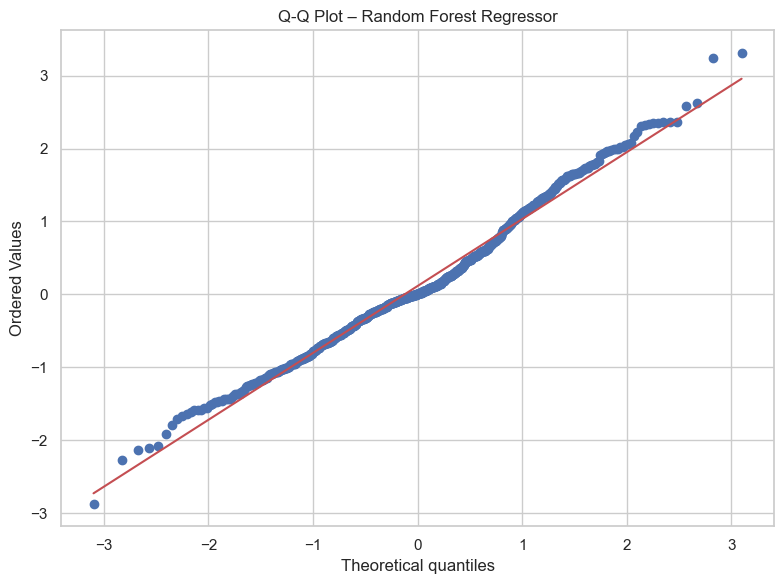

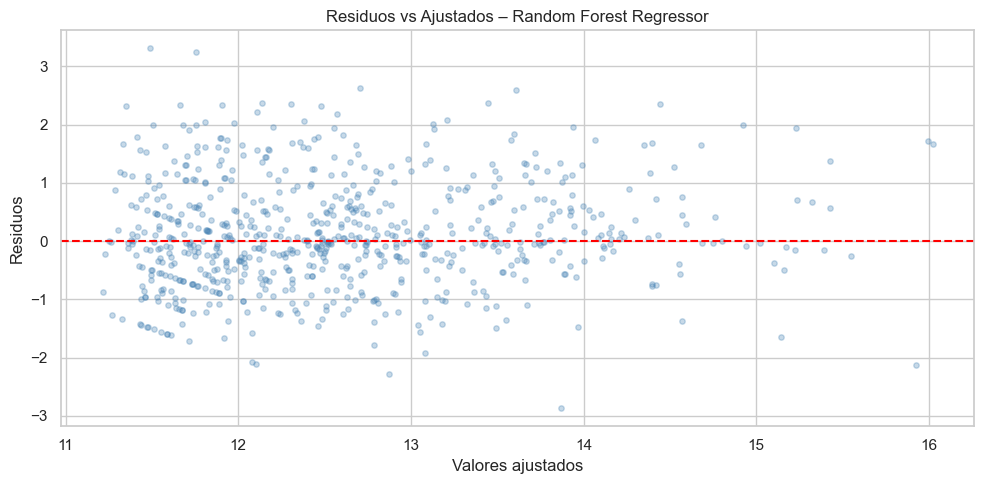

In [ ]:
# Q-Q plot y residuos vs ajustados para el mejor modelo
fig1 = plot_qq(residuos_mejor, mejor_modelo_nombre)
fig1.savefig("plots/qq_plot_mejor.png", dpi=150, bbox_inches='tight')
plt.show()

fig2 = plot_residuals_vs_fitted(y_test, y_pred_mejor, mejor_modelo_nombre)
fig2.savefig("plots/residuals_vs_fitted_mejor.png", dpi=150, bbox_inches='tight')
plt.show()


## 4.9 Análisis de error por rango de nota

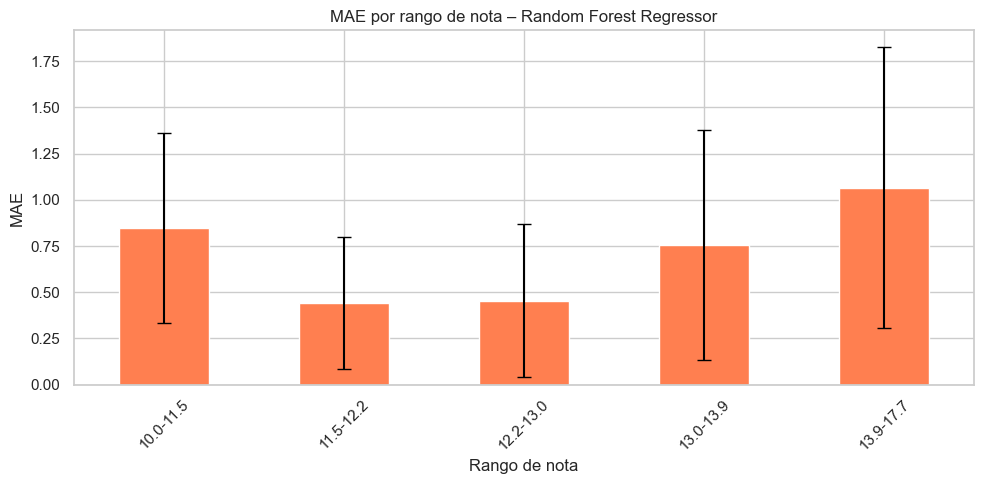

In [ ]:
fig = error_by_range(y_test, y_pred_mejor, mejor_modelo_nombre, n_bins=5)
fig.savefig("plots/error_by_range_mejor.png", dpi=150, bbox_inches='tight')
plt.show()

## 4.10 Conclusiones de Regresión

- **Mejor modelo:** El análisis muestra que los modelos **Random Forest y Gradient Boosting** son superior a métodos lineales, con R² significativamente más alto (~0.53-0.54 vs 0.39 para Ridge/Lasso).

- **Dificultad del problema:** Predecir la nota del 2do semestre sin usar información del 2do semestre es inherentemente difícil debido a:
  - Variabilidad individual alta en el comportamiento de estudiantes
  - Cambios en circunstancias personales entre semestres
  - Bajo poder predictivo de características estáticas

- **Variables más predictivas:** Las correlaciones confirman que el desempeño del 1er semestre es el mejor predictor:
  - nota_media_1sem (correlación > 0.6)
  - asignaturas_1sem_aprobadas
  - asignaturas_1sem_evaluadas
  - Variables de admisión (nota de acceso)

- **Diagnóstico de residuos:** El Q-Q plot y la distribución de residuos muestran que los residuos no son perfectamente normales, reflejando outliers en el desempeño estudiantil que son difíciles de predecir.

- **Variación por rango:** El análisis de error por rango revela si hay sesgo sistemático (ej: peor desempeño prediciendo notas altas vs bajas), útil para identificar limitaciones del modelo.

- **Metodología:** La exclusión de variables del 2do semestre es metodológicamente correcta para evitar leakage, aunque reduce el R² máximo alcanzable.